# Leakage Audit

This notebook audits the timing of the 55 predictors used in the hypothesis test, so that it is clear which information a recommendation made at time t could really have known at time t.

> **Hypothesis test: anonymisation cost (classification).** The audit reads the same inputs as the hypothesis notebooks (the `K3_regions` workbook in `data/raw` and the model state tables in `data/processed/hypothesis_testing`). It trains no model, writes no file and changes no hypothesis notebook. All results are shown in the notebook output only.

The audit follows the point-in-time principle: a feature for the state (Property_ID, Prediction_Time) may only use records whose timestamp is not later than Prediction_Time. The notebook first explains the principle with one state and one customer as worked examples, then counts for every feature family how many of the 431 states break it, and finally runs sanity checks on the model state tables.

## Why Timing Matters

A state in the model state table describes a property at the moment a new asset category was documented, and the target is the next different category documented afterwards. The prediction time t is therefore the Created_At of the current category event. A recommendation system running in production at time t would only have access to what exists at time t, so any value in a feature that was written after t is information from the future. Such a feature can raise the measured accuracy without being usable in practice, and it can also hide or exaggerate the difference between the source release and the anonymised release.

The check is simple in principle. For each feature family the notebook looks for the table and the timestamp column that the family comes from, compares that timestamp with Prediction_Time for every state, and counts the states where the timestamp is later. Three outcomes are possible. The family is filtered by the pipeline and the count is zero, the family is not filtered and the count is positive, or the family has no timestamp at all so that the question cannot be answered from the data and has to be handled as an assumption.

## What The Prediction Time t Is

The prediction time is not the first asset of a property and not the creation of the customer account. For every property the assets are ordered by Created_At and turned into a sequence of categories, simultaneous events of different categories are excluded because their order cannot be known, and repeated consecutive entries of the same category are merged. Every event of this sequence that is followed by a different category becomes one state, the prediction time t of the state is the Created_At of that event, and the target is the next different category. A property therefore has as many states as it has category changes, each with its own t, and the last category of the sequence has no next category and gives no state.

As an example, if a property documents an Electronics asset at 14:24 and a Furniture asset at 14:38, the state at t = 14:24 describes the property with one documented asset and has the target Furniture. The Furniture asset belongs to the future of that state and may only appear as the answer.

## Data Sources

The model state table of the anonymised release is the main input. The source release table is read as well, only to confirm that both releases share the same states and timestamps. The workbook tables are used to find the timestamp of each family.

In [1]:
# -------------------------------------------------------------------
# Data Sources
# -------------------------------------------------------------------
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

WORKBOOK_PATH = Path("../../../data/raw/Household_Insurance_Synthetic_Dataset_v2_K3_regions.xlsx")
STATE_REGIONS_PATH = Path("../../../data/processed/hypothesis_testing/regions_anonymised/model_state.csv")
STATE_SOURCE_PATH = Path("../../../data/processed/hypothesis_testing/source_dataset/model_state.csv")

for path in [WORKBOOK_PATH, STATE_REGIONS_PATH, STATE_SOURCE_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

state = pd.read_csv(STATE_REGIONS_PATH, parse_dates=["Prediction_Time"])
state_source = pd.read_csv(STATE_SOURCE_PATH, parse_dates=["Prediction_Time"])

tables = {
    name: pd.read_excel(WORKBOOK_PATH, sheet_name=name)
    for name in ["customers", "customer_profiles", "properties", "assets", "ai_analysis", "property_videos", "Data Dictionary"]
}

customers = tables["customers"]
profiles = tables["customer_profiles"]
properties = tables["properties"]
assets = tables["assets"]
ai_analysis = tables["ai_analysis"]
videos = tables["property_videos"]

# Timestamps must be real dates before they are compared with the prediction time.
customers["Account_Created"] = pd.to_datetime(customers["Account_Created"])
properties["Created_At"] = pd.to_datetime(properties["Created_At"])
assets["Created_At"] = pd.to_datetime(assets["Created_At"])
ai_analysis["Created_At"] = pd.to_datetime(ai_analysis["Created_At"])
videos["Created_At"] = pd.to_datetime(videos["Created_At"])

print(f"States (anonymised release): {len(state):,}")
print(f"States (source release):     {len(state_source):,}")
print(f"Properties with a state:     {state['Property_ID'].nunique():,} of {len(properties):,}")
print(f"Customers with a state:      {state['Customer_ID'].nunique():,} of {len(customers):,}")
print(f"Prediction_Time range:       {state['Prediction_Time'].min()} to {state['Prediction_Time'].max()}")

States (anonymised release): 431
States (source release):     431
Properties with a state:     234 of 795
Customers with a state:      198 of 500
Prediction_Time range:       2024-09-19 06:19:28 to 2026-09-07 03:24:49


## The 55 Predictors By Family

The model state table has 60 columns. Five of them identify the state or hold the target (Property_ID, Customer_ID, Prediction_Time, Next_Category_ID and Next_Category), and the remaining 55 are the predictors of the full feature set. They are grouped here in the same seven families as in the methodology draft. The `no_ai` feature set removes the 13 columns whose names start with `ai_` and the `pure_record` feature set keeps only the two documented families.

In [2]:
# -------------------------------------------------------------------
# Feature Families
# -------------------------------------------------------------------
IDENTIFIERS = ["Property_ID", "Customer_ID", "Prediction_Time", "Next_Category_ID", "Next_Category"]

FAMILIES = {
    "documented category counts": [c for c in state.columns if c.startswith("documented_count_CAT-")],
    "documented aggregates": [
        "documented_asset_count", "documented_category_count", "documented_value_total",
        "documented_replacement_cost_total", "mean_evidence_rating",
    ],
    "AI features": [c for c in state.columns if c.startswith("ai_")],
    "property context": [
        "Property_Type", "Occupancy_Type", "Number_Of_Occupants", "Number_Of_Bedrooms",
        "Property_Valuation_AUD", "Is_Home_Insured", "Insurance_Coverage_Type", "Is_Primary",
    ],
    "customer profile": [
        "Financial_Literacy_Band", "Insurance_Confidence_1_5", "Engagement_Tier", "Preferred_Channel",
        "Preferred_Explanation_Style", "Notification_Opt_In", "Household_Type", "Income_Band",
        "Tenure_Months", "Prior_Claim_Experience", "Underinsurance_Awareness",
    ],
    "customer attributes": ["Age_Band", "Gender", "State", "Occupation", "Membership_Level", "Account_Status"],
    "video": [c for c in state.columns if "video" in c or c in ("total_rooms_covered", "total_items_detected")],
}

assigned = [column for columns in FAMILIES.values() for column in columns]
predictors = [c for c in state.columns if c not in IDENTIFIERS]

assert len(assigned) == len(set(assigned)), "A column belongs to two families."
assert sorted(assigned) == sorted(predictors), "Families do not cover the predictors exactly."

SOURCE_OF_FAMILY = {
    "documented category counts": ("assets", "Created_At"),
    "documented aggregates": ("assets", "Created_At"),
    "AI features": ("ai_analysis", "Created_At"),
    "property context": ("properties", "Created_At"),
    "customer profile": ("customer_profiles", "none recorded"),
    "customer attributes": ("customers", "Account_Created"),
    "video": ("property_videos", "Created_At"),
}

overview = pd.DataFrame(
    [
        {"family": name, "features": len(columns), "table": SOURCE_OF_FAMILY[name][0], "timestamp": SOURCE_OF_FAMILY[name][1]}
        for name, columns in FAMILIES.items()
    ]
)
print(overview.to_string(index=False))
print(f"\nPredictors: {len(predictors)}")
print(f"no_ai feature set:       {len([c for c in predictors if not c.startswith('ai_')])} features")
print(f"pure_record feature set: {len(FAMILIES['documented category counts']) + len(FAMILIES['documented aggregates'])} features")

                    family  features             table       timestamp
documented category counts         7            assets      Created_At
     documented aggregates         5            assets      Created_At
               AI features        13       ai_analysis      Created_At
          property context         8        properties      Created_At
          customer profile        11 customer_profiles   none recorded
       customer attributes         6         customers Account_Created
                     video         5   property_videos      Created_At

Predictors: 55
no_ai feature set:       42 features
pure_record feature set: 12 features


## Worked Example 1: One State Followed Through Time

The first example takes one real state and lays out every record that feeds its features on a time line. The state is chosen automatically as the state with the fewest documented assets among those where all four sources (property record, customer account, AI analysis and video) carry a timestamp later than Prediction_Time, so that every kind of timing problem is visible in one place. Records on or before the prediction time are what the model is allowed to use, and records after it are information from the future.

In [3]:
# -------------------------------------------------------------------
# Example State
# -------------------------------------------------------------------
ai_rank1 = ai_analysis[ai_analysis["Candidate_Rank"] == 1][["Asset_ID", "Created_At"]].rename(columns={"Created_At": "AI_Created_At"})
ai_assets = assets[["Asset_ID", "Property_ID", "Category", "Created_At"]].merge(ai_rank1, on="Asset_ID", how="inner")

flags = state[["Property_ID", "Customer_ID", "Prediction_Time", "documented_asset_count", "Next_Category"]].copy()
flags = flags.merge(properties[["Property_ID", "Created_At"]].rename(columns={"Created_At": "Property_Created"}), on="Property_ID")
flags = flags.merge(customers[["Customer_ID", "Account_Created"]], on="Customer_ID")

first_video = videos.groupby("Property_ID")["Created_At"].min().rename("First_Video_Created")
flags = flags.merge(first_video, on="Property_ID", how="left")

documented = flags[["Property_ID", "Prediction_Time"]].merge(ai_assets, on="Property_ID")
documented = documented[documented["Created_At"] <= documented["Prediction_Time"]]
late_ai = (
    documented[documented["AI_Created_At"] > documented["Prediction_Time"]]
    .groupby(["Property_ID", "Prediction_Time"]).size().rename("late_ai_rows").reset_index()
)
flags = flags.merge(late_ai, on=["Property_ID", "Prediction_Time"], how="left").fillna({"late_ai_rows": 0})

candidates = flags[
    (flags["Property_Created"] > flags["Prediction_Time"])
    & (flags["Account_Created"] > flags["Prediction_Time"])
    & (flags["First_Video_Created"] > flags["Prediction_Time"])
    & (flags["late_ai_rows"] > 0)
].sort_values(["documented_asset_count", "Property_ID", "Prediction_Time"])

example = candidates.iloc[0]
print(f"States where all four sources are later than t: {len(candidates)}")
print(f"\nExample state: {example['Property_ID']} at {example['Prediction_Time']}")
print(f"Customer:      {example['Customer_ID']}")
print(f"Target:        next category is {example['Next_Category']}")

States where all four sources are later than t: 12

Example state: PRP-000026 at 2025-07-16 14:24:48
Customer:      CUS-0A58AE52
Target:        next category is Furniture


In [4]:
# -------------------------------------------------------------------
# Time Line Of The Example State
# -------------------------------------------------------------------
pid, t = example["Property_ID"], example["Prediction_Time"]

events = [("t (prediction time)", "-", t, "-")]
events.append(("Customer account created", "customers", example["Account_Created"], "stored value is copied into the state"))
events.append(("Property record created", "properties", example["Property_Created"], "stored value is copied into the state"))

for _, row in assets[assets["Property_ID"] == pid].sort_values("Created_At").iterrows():
    used = "counted in the documented features" if row["Created_At"] <= t else "not counted (documented later)"
    events.append((f"Asset documented ({row['Category']})", "assets", row["Created_At"], used))
for _, row in videos[videos["Property_ID"] == pid].sort_values("Created_At").iterrows():
    events.append((f"Video created ({row['Duration_Seconds']:.0f} s)", "property_videos", row["Created_At"], "counted in the video features"))
for _, row in ai_assets[(ai_assets["Property_ID"] == pid) & (ai_assets["Created_At"] <= t)].sort_values("AI_Created_At").iterrows():
    events.append((f"AI analysis of a {row['Category']} asset", "ai_analysis", row["AI_Created_At"], "counted in the AI features"))

timeline = pd.DataFrame(events, columns=["event", "table", "timestamp", "used by the features at t"]).sort_values("timestamp").reset_index(drop=True)
gap_seconds = (timeline["timestamp"] - t).dt.total_seconds()
timeline["relative_to_t"] = np.where(gap_seconds <= 0, "known at t", "AFTER t")
timeline.loc[timeline["event"].str.startswith("t "), "relative_to_t"] = "-"
timeline["gap_from_t"] = [
    "0" if g == 0 else f"{g:+,.0f} s" if abs(g) < 3600 else f"{g / 3600:+,.1f} h" if abs(g) < 172800 else f"{g / 86400:+,.1f} days"
    for g in gap_seconds
]
timeline["leak"] = np.where(
    (timeline["relative_to_t"] == "AFTER t") & timeline["used by the features at t"].str.startswith(("counted", "stored")), "LEAK", ""
)
print(timeline[["event", "table", "timestamp", "relative_to_t", "gap_from_t", "used by the features at t", "leak"]].to_string(index=False))

used_assets = (assets[assets["Property_ID"] == pid]["Created_At"] <= t).sum()
print(f"\nAssets documented by t:                {used_assets}  (model state: documented_asset_count = {int(example['documented_asset_count'])})")
print(f"Video features in the model state:     video_count = {int(state.loc[state['Property_ID'].eq(pid) & state['Prediction_Time'].eq(t), 'video_count'].iloc[0])}")

                             event           table           timestamp relative_to_t  gap_from_t             used by the features at t leak
               t (prediction time)               - 2025-07-16 14:24:48             -           0                                     -     
    Asset documented (Electronics)          assets 2025-07-16 14:24:48    known at t           0    counted in the documented features     
AI analysis of a Electronics asset     ai_analysis 2025-07-16 14:27:03       AFTER t      +135 s            counted in the AI features LEAK
      Asset documented (Furniture)          assets 2025-07-16 14:38:31       AFTER t      +823 s        not counted (documented later)     
      Asset documented (Furniture)          assets 2025-07-16 14:40:49       AFTER t      +961 s        not counted (documented later)     
      Asset documented (Furniture)          assets 2025-07-16 14:43:42       AFTER t    +1,134 s        not counted (documented later)     
    Asset documented

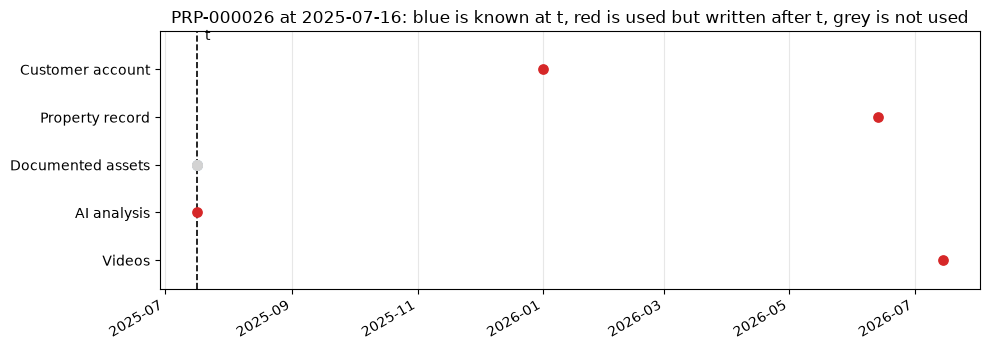

In [5]:
# -------------------------------------------------------------------
# Time Line Figure
# -------------------------------------------------------------------
rows = ["Customer account", "Property record", "Documented assets", "AI analysis", "Videos"]
points = {
    "Customer account": [example["Account_Created"]],
    "Property record": [example["Property_Created"]],
    "Documented assets": list(assets.loc[assets["Property_ID"] == pid, "Created_At"]),
    "AI analysis": list(ai_assets.loc[(ai_assets["Property_ID"] == pid) & (ai_assets["Created_At"] <= t), "AI_Created_At"]),
    "Videos": list(videos.loc[videos["Property_ID"] == pid, "Created_At"]),
}

fig, ax = plt.subplots(figsize=(10, 3.6))
for y, name in enumerate(rows[::-1]):
    for moment in points[name]:
        colour = "tab:blue" if moment <= t else "tab:red"
        if name == "Documented assets" and moment > t:
            colour = "lightgrey"
        ax.scatter(moment, y, color=colour, s=45, zorder=3)
ax.axvline(t, color="black", linestyle="--", linewidth=1.2)
ax.text(t, len(rows) - 0.45, "  t", va="bottom", ha="left")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels(rows[::-1])
ax.set_ylim(-0.6, len(rows) - 0.2)
ax.set_title(f"{pid} at {t:%Y-%m-%d}: blue is known at t, red is used but written after t, grey is not used")
ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The example shows the three situations described above. The documented assets are all on or before t because the pipeline joins the asset table with the condition Created_At <= Prediction_Time, which is why the two documented families are clean. The property record, the customer account and the video are written later than t, yet their values are copied unchanged into the state, because those tables hold one current row per property or per customer and the pipeline does not filter them by time. The AI analysis is a mixed case, because the asset itself is documented by t and therefore counted, while some of its analysis rows carry a later timestamp.

## Worked Example 2: One Customer Across Several States

The customer attributes and the customer profile are stored once per customer, so the same stored value is attached to every state of that customer whatever the prediction time is. The second example takes a customer with several states and compares the stored Tenure_Months, which the data dictionary defines as the months since account creation, with the tenure that the customer really had at each prediction time.

In [6]:
# -------------------------------------------------------------------
# Example Customer
# -------------------------------------------------------------------
per_customer = (
    state.merge(customers[["Customer_ID", "Account_Created"]], on="Customer_ID")
    .assign(account_after_t=lambda d: d["Account_Created"] > d["Prediction_Time"])
    .groupby("Customer_ID")
    .agg(states=("Property_ID", "size"), states_before_account=("account_after_t", "sum"))
)
mixed = per_customer[(per_customer["states"] >= 3) & (per_customer["states_before_account"].between(1, per_customer["states"] - 1))]
tenure_gap = (
    state.merge(customers[["Customer_ID", "Account_Created"]], on="Customer_ID")
    .assign(gap=lambda d: d["Tenure_Months"] - ((d["Prediction_Time"] - d["Account_Created"]).dt.days / 30.44).clip(lower=0))
    .groupby("Customer_ID")["gap"].mean()
)
customer_id = tenure_gap.loc[mixed.index].sort_values(ascending=False).index[0]

stored_tenure = int(profiles.loc[profiles["Customer_ID"] == customer_id, "Tenure_Months"].iloc[0])
account_created = customers.loc[customers["Customer_ID"] == customer_id, "Account_Created"].iloc[0]

view = state.loc[state["Customer_ID"] == customer_id, ["Property_ID", "Prediction_Time", "Tenure_Months", "Age_Band", "State", "Account_Status"]].sort_values("Prediction_Time").copy()
view["account_created"] = account_created
view["account_exists_at_t"] = view["account_created"] <= view["Prediction_Time"]
view["tenure_at_t_months"] = ((view["Prediction_Time"] - view["account_created"]).dt.days / 30.44).round(1)
view["tenure_at_t_months"] = view["tenure_at_t_months"].clip(lower=0)

print(f"Customer {customer_id}, account created {account_created:%Y-%m-%d}, stored Tenure_Months = {stored_tenure}")
print(view.to_string(index=False))

Customer CUS-E4D2E40B, account created 2025-08-16, stored Tenure_Months = 12
Property_ID     Prediction_Time  Tenure_Months Age_Band State Account_Status account_created  account_exists_at_t  tenure_at_t_months
 PRP-000754 2025-07-18 05:08:22             12      55+ North         active      2025-08-16                False                 0.0
 PRP-000754 2025-07-18 05:12:42             12      55+ North         active      2025-08-16                False                 0.0
 PRP-000449 2026-02-16 03:07:07             12      55+ North         active      2025-08-16                 True                 6.0


In the table the column Tenure_Months is the same stored number in every row, whereas tenure_at_t_months is what a system running at that time would have known (zero or negative values are clipped to zero and mean that the account did not exist yet). The stored number describes the customer at the end of the data window and not at each prediction time. The same reasoning applies to Age_Band, Account_Status and Membership_Level, which are also single current values.

## Worked Example 3: Three Customers Side By Side

The last example compares three customers whose states differ in how much information from the future they carry. The first state has every kind of later record, the second has an account that existed at t but a stored tenure that does not match it, and the third is close to point-in-time. The gaps are measured from t, so a positive gap means that the record was written after the prediction time.

In [7]:
# -------------------------------------------------------------------
# Three Customers
# -------------------------------------------------------------------
EXAMPLES = [
    ("CUS-0A58AE52", "PRP-000026", "2025-07-16 14:24:48"),
    ("CUS-F89E3051", "PRP-000021", "2025-05-08 01:58:51"),
    ("CUS-97536F32", "PRP-000052", "2026-05-21 20:57:12"),
]


def gap_text(moment, t):
    if pd.isna(moment):
        return "none"
    days = (moment - t).total_seconds() / 86400
    return f"{days:+,.0f} days" + (" (after t)" if days > 0 else " (known at t)")


rows = []
for customer, property_id, moment in EXAMPLES:
    t = pd.Timestamp(moment)
    row = state[(state["Property_ID"] == property_id) & (state["Prediction_Time"] == t)]
    assert len(row) == 1 and row["Customer_ID"].iloc[0] == customer, (customer, property_id, moment)
    row = row.iloc[0]

    created = customers.loc[customers["Customer_ID"] == customer, "Account_Created"].iloc[0]
    property_created = properties.loc[properties["Property_ID"] == property_id, "Created_At"].iloc[0]
    first_video = videos.loc[videos["Property_ID"] == property_id, "Created_At"].min()
    own_ai = ai_assets[(ai_assets["Property_ID"] == property_id) & (ai_assets["Created_At"] <= t)]
    late_rows = own_ai[own_ai["AI_Created_At"] > t]
    tenure_at_t = max((t - created).days / 30.44, 0)

    rows.append(
        {
            "customer": customer,
            "state": f"{property_id} at {t:%Y-%m-%d}",
            "assets known at t": int(row["documented_asset_count"]),
            "account created": gap_text(created, t),
            "property created": gap_text(property_created, t),
            "first video": gap_text(first_video, t),
            "AI rows after t": len(late_rows),
            "stored Tenure_Months": int(row["Tenure_Months"]),
            "tenure at t (months)": round(tenure_at_t, 1),
        }
    )

print(pd.DataFrame(rows).set_index("customer").T.to_string())

customer                          CUS-0A58AE52              CUS-F89E3051              CUS-97536F32
state                 PRP-000026 at 2025-07-16  PRP-000021 at 2025-05-08  PRP-000052 at 2026-05-21
assets known at t                            1                         1                        36
account created            +168 days (after t)    -362 days (known at t)  -1,157 days (known at t)
property created           +332 days (after t)       +279 days (after t)     -33 days (known at t)
first video                +363 days (after t)       +449 days (after t)                      none
AI rows after t                              1                         0                         0
stored Tenure_Months                         7                        27                        40
tenure at t (months)                       0.0                      11.9                      38.0


Reading the table customer by customer, the first state carries a later account, a later property record, a later video and a later AI analysis, and its stored tenure of several months belongs to an account that did not exist at t. The second state has an account that existed at t, yet the stored tenure is far longer than the tenure at t because it was computed at the end of the window, and the property record and the video are still later. The third state is close to point-in-time, with an account and a property record that exist at t, no video and no later AI analysis, and a stored tenure that is only slightly longer than the tenure at t. Most states lie between these cases, and the family table below counts them over all 431 states.

## Does Tenure_Months Describe The Customer At The End Of The Window?

The customer profile table has no timestamp, so its measurement time cannot be read from the data. The data dictionary defines Tenure_Months as the months since account creation but does not say as of which date, so it offers an indirect way to estimate the measurement time, because the number of months since account creation can be turned into an implied snapshot date by adding it to Account_Created. If the profile were measured at different times for different customers the implied dates would be scattered, and if it was measured once the implied dates would cluster around one date.

In [8]:
# -------------------------------------------------------------------
# Implied Snapshot Date Of The Customer Profile
# -------------------------------------------------------------------
tenure = profiles[["Customer_ID", "Tenure_Months"]].merge(customers[["Customer_ID", "Account_Created"]], on="Customer_ID")
tenure["implied_snapshot"] = tenure["Account_Created"] + pd.to_timedelta(tenure["Tenure_Months"] * 30.44, unit="D")

dictionary = tables["Data Dictionary"]
definition = dictionary.loc[dictionary["Column Name"].eq("Tenure_Months"), ["Dataset", "Column Name", "Type", "Description"]]
print("Definition in the data dictionary:")
print(definition.to_string(index=False))
print()

print("Implied snapshot date of the customer profile (one value per customer):")
print(tenure["implied_snapshot"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_string())

snapshot = tenure["implied_snapshot"].median()
months_since_creation = (pd.Timestamp(snapshot) - tenure["Account_Created"]).dt.days / 30.44
print(f"\nCorrelation of Tenure_Months with months from account creation to the median snapshot: {np.corrcoef(months_since_creation, tenure['Tenure_Months'])[0, 1]:.4f}")

before_snapshot = (state["Prediction_Time"] < snapshot).mean()
print(f"Median implied snapshot date: {snapshot:%Y-%m-%d}")
print(f"States with Prediction_Time before that date: {(state['Prediction_Time'] < snapshot).sum()} of {len(state)} ({before_snapshot:.1%})")

Definition in the data dictionary:
          Dataset   Column Name    Type                    Description
customer_profiles Tenure_Months Integer Months since account creation.

Implied snapshot date of the customer profile (one value per customer):
count                              500
mean     2026-08-02 20:16:51.455999744
min                2026-07-17 23:02:24
5%                 2026-07-20 01:55:12
25%                2026-07-27 10:19:12
50%                2026-08-02 11:02:24
75%                2026-08-10 10:33:36
95%         2026-08-15 18:20:09.600000
max                2026-08-18 00:57:36

Correlation of Tenure_Months with months from account creation to the median snapshot: 0.9997
Median implied snapshot date: 2026-08-02
States with Prediction_Time before that date: 427 of 431 (99.1%)


## Counting Future Information By Family

The next table is the main result of the audit. For every family it counts the states in which the source records carry a timestamp later than Prediction_Time. The documented families are recomputed from the asset table to confirm that the pipeline filtering is exact. The AI family is counted in two ways, once for the Candidate_Rank 1 analysis rows of the assets documented by t (the unit used in the methodology draft) and once as the number of states affected.

In [9]:
# -------------------------------------------------------------------
# Documented Families: Recomputation From The Asset Table
# -------------------------------------------------------------------
pairs = state[["Property_ID", "Prediction_Time"]].merge(
    assets[["Asset_ID", "Property_ID", "Category_ID", "Created_At", "Evidence_Rating_0_5"]], on="Property_ID"
)
known = pairs[pairs["Created_At"] <= pairs["Prediction_Time"]]

recomputed = known.groupby(["Property_ID", "Prediction_Time"]).agg(
    asset_count=("Asset_ID", "nunique"),
    category_count=("Category_ID", "nunique"),
    mean_rating=("Evidence_Rating_0_5", "mean"),
).reset_index()
check = state.merge(recomputed, on=["Property_ID", "Prediction_Time"], how="left")

by_category = known.groupby(["Property_ID", "Prediction_Time", "Category_ID"]).size().unstack(fill_value=0).reset_index()
check = check.merge(by_category, on=["Property_ID", "Prediction_Time"], how="left")

category_columns = FAMILIES["documented category counts"]
category_match = all(
    (check[f"documented_count_{cat.split('_')[-1]}"] == check[cat.split("_")[-1]].fillna(0)).all()
    for cat in category_columns
)

print("Documented features recomputed with Created_At <= Prediction_Time:")
print(f"- documented_asset_count equal in {(check['documented_asset_count'] == check['asset_count']).mean():.1%} of states")
print(f"- documented_category_count equal in {(check['documented_category_count'] == check['category_count']).mean():.1%} of states")
print(f"- mean_evidence_rating equal in {np.isclose(check['mean_evidence_rating'], check['mean_rating']).mean():.1%} of states")
print(f"- the seven documented_count_CAT columns all equal: {category_match}")

# The AI predictors come from the analysis rows of the assets documented by t, not from the valuation table.
ai_known = known.merge(
    ai_analysis[ai_analysis["Candidate_Rank"] == 1][["Asset_ID", "Estimated_Value_AI", "Category_Match", "User_Accepted_Suggestion"]],
    on="Asset_ID",
    how="inner",
)
ai_recomputed = ai_known.groupby(["Property_ID", "Prediction_Time"]).agg(
    value_total=("Estimated_Value_AI", "sum"),
    match_rate=("Category_Match", "mean"),
    acceptance_rate=("User_Accepted_Suggestion", "mean"),
).reset_index()
ai_check = state.merge(ai_recomputed, on=["Property_ID", "Prediction_Time"], how="left")

print("\nAI predictors recomputed from ai_analysis (Candidate_Rank 1, assets documented by t):")
print(f"- ai_estimated_value_total equal in {np.isclose(ai_check['ai_estimated_value_total'], ai_check['value_total']).mean():.1%} of states")
print(f"- ai_category_match_rate equal in {np.isclose(ai_check['ai_category_match_rate'], ai_check['match_rate']).mean():.1%} of states")
print(f"- ai_suggestion_acceptance_rate equal in {np.isclose(ai_check['ai_suggestion_acceptance_rate'], ai_check['acceptance_rate']).mean():.1%} of states")

Documented features recomputed with Created_At <= Prediction_Time:
- documented_asset_count equal in 100.0% of states
- documented_category_count equal in 100.0% of states
- mean_evidence_rating equal in 100.0% of states
- the seven documented_count_CAT columns all equal: True

AI predictors recomputed from ai_analysis (Candidate_Rank 1, assets documented by t):
- ai_estimated_value_total equal in 100.0% of states
- ai_category_match_rate equal in 100.0% of states
- ai_suggestion_acceptance_rate equal in 100.0% of states


In [10]:
# -------------------------------------------------------------------
# Family Table
# -------------------------------------------------------------------
n_states = len(state)

# Property context and customer attributes: one current row per property or customer.
with_property = state.merge(properties[["Property_ID", "Created_At"]], on="Property_ID")
property_late = int((with_property["Created_At"] > with_property["Prediction_Time"]).sum())

with_customer = state.merge(customers[["Customer_ID", "Account_Created"]], on="Customer_ID")
account_late = int((with_customer["Account_Created"] > with_customer["Prediction_Time"]).sum())

# AI features: analysis rows (Candidate_Rank 1) of assets that were documented by t.
rank1 = state[["Property_ID", "Prediction_Time"]].merge(ai_assets, on="Property_ID")
rank1 = rank1[rank1["Created_At"] <= rank1["Prediction_Time"]]
rank1_late = rank1[rank1["AI_Created_At"] > rank1["Prediction_Time"]]
ai_rows = len(rank1)
ai_late_rows = len(rank1_late)
ai_late_states = rank1_late[["Property_ID", "Prediction_Time"]].drop_duplicates().shape[0]

# Video features: all videos of the property, whatever their creation time.
video_pairs = state[["Property_ID", "Prediction_Time"]].merge(videos[["Property_ID", "Created_At"]], on="Property_ID")
states_with_video = video_pairs[["Property_ID", "Prediction_Time"]].drop_duplicates().shape[0]
video_late_states = video_pairs[video_pairs["Created_At"] > video_pairs["Prediction_Time"]][["Property_ID", "Prediction_Time"]].drop_duplicates().shape[0]

per_property = videos.groupby("Property_ID").agg(n=("Video_ID", "count"), seconds=("Duration_Seconds", "sum"))
joined = state.merge(per_property, on="Property_ID", how="left").fillna({"n": 0, "seconds": 0})
video_uses_all = bool((joined["video_count"] == joined["n"]).all() and np.isclose(joined["total_video_duration_seconds"], joined["seconds"]).all())

family_table = pd.DataFrame(
    [
        ["documented category counts", 7, "assets", "Created_At", "yes, Created_At <= t", f"0 of {n_states}", "keep, point-in-time clean"],
        ["documented aggregates", 5, "assets", "Created_At", "yes, Created_At <= t", f"0 of {n_states}", "keep, point-in-time clean"],
        ["AI features", 13, "ai_analysis", "Created_At", "assets only, analysis rows not", f"{ai_late_states} of {n_states} states ({ai_late_rows} of {ai_rows} rows)", "report, test with and without"],
        ["property context", 8, "properties", "Created_At", "no", f"{property_late} of {n_states}", "static, state the assumption"],
        ["customer profile", 11, "customer_profiles", "none recorded", "no", f"{int((state['Prediction_Time'] < snapshot).sum())} of {n_states} (indirect, from Tenure_Months)", "static, state the assumption"],
        ["customer attributes", 6, "customers", "Account_Created", "no", f"{account_late} of {n_states}", "static, state the assumption"],
        ["video", 5, "property_videos", "Created_At", "no, all videos used" if video_uses_all else "partly", f"{video_late_states} of {states_with_video} states with a video", "report, own family"],
    ],
    columns=["family", "features", "table", "timestamp", "filtered by pipeline", "states with later records", "treatment"],
)
print(family_table.to_string(index=False))
print(f"\nTotal predictors: {family_table['features'].sum()}")

                    family  features             table       timestamp           filtered by pipeline                 states with later records                     treatment
documented category counts         7            assets      Created_At           yes, Created_At <= t                                  0 of 431     keep, point-in-time clean
     documented aggregates         5            assets      Created_At           yes, Created_At <= t                                  0 of 431     keep, point-in-time clean
               AI features        13       ai_analysis      Created_At assets only, analysis rows not      175 of 431 states (465 of 2562 rows) report, test with and without
          property context         8        properties      Created_At                             no                                264 of 431  static, state the assumption
          customer profile        11 customer_profiles   none recorded                             no 427 of 431 (indirect, from T

Reading the table from top to bottom, the two documented families are point-in-time clean and are the only families for which that statement is exact. The AI analysis rows are an intermediate case, since the pipeline selects the assets by time but the analysis rows of those assets can carry a later timestamp, and the AI features are in any case evaluated separately through the no_ai feature set. The property record, the customer account and the video are written later than t in a large share of the states, and the customer profile cannot be tested at all, so for these families the time invariance of the stored value has to be stated as an assumption in the paper.

## How Far In The Future Are The Later Records?

A later record is less worrying when it is written a few seconds after t than when it is written months later. The next table gives the size of the gap for the records counted above.

In [11]:
# -------------------------------------------------------------------
# Size Of The Gap
# -------------------------------------------------------------------
def gap_summary(label, gap, unit):
    gap = gap.dropna()
    return {
        "source": label,
        "unit": unit,
        "n": len(gap),
        "median": round(gap.median(), 1),
        "p75": round(gap.quantile(0.75), 1),
        "p95": round(gap.quantile(0.95), 1),
        "max": round(gap.max(), 1),
    }

property_gap = (with_property["Created_At"] - with_property["Prediction_Time"]).dt.total_seconds() / 86400
account_gap = (with_customer["Account_Created"] - with_customer["Prediction_Time"]).dt.total_seconds() / 86400
video_gap = (
    video_pairs.assign(gap=(video_pairs["Created_At"] - video_pairs["Prediction_Time"]).dt.total_seconds() / 86400)
    .groupby(["Property_ID", "Prediction_Time"])["gap"].max()
)
ai_gap = (rank1_late["AI_Created_At"] - rank1_late["Prediction_Time"]).dt.total_seconds() / 3600

gaps = pd.DataFrame(
    [
        gap_summary("property record created after t", property_gap[property_gap > 0], "days"),
        gap_summary("customer account created after t", account_gap[account_gap > 0], "days"),
        gap_summary("latest video of the property after t", video_gap[video_gap > 0], "days"),
        gap_summary("AI analysis row written after t", ai_gap, "hours"),
    ]
)
print(gaps.to_string(index=False))

                              source  unit   n  median   p75    p95     max
     property record created after t  days 264   266.8 326.7  499.3   661.4
    customer account created after t  days 121   168.0 274.0  408.9   617.3
latest video of the property after t  days  80   279.3 370.3  424.9   572.9
     AI analysis row written after t hours 465     1.0 113.6 3089.7 16656.0


## Video Features

The five video features come from the table property_videos. Two questions are checked here, whether the columns Rooms_Covered and Items_Detected can be treated as AI outputs, and whether mean_video_duration_seconds carries information that the other video columns do not. The data dictionary of the release is printed for the two columns, and the relations between the video columns are computed on the 94 states that have a video.

In [12]:
# -------------------------------------------------------------------
# Video Columns
# -------------------------------------------------------------------
keys_video = ["Property_ID", "Prediction_Time"]
dictionary = tables["Data Dictionary"]
print("Data dictionary of the release (property_videos):")
print(dictionary.loc[dictionary["Dataset"].eq("property_videos") & dictionary["Column Name"].isin(["Rooms_Covered", "Items_Detected"]), ["Column Name", "Type", "Allowed Values / Format", "Description"]].to_string(index=False))

has_video = state[state["video_count"] > 0]
print(f"\nStates with a video: {len(has_video)} of {len(state)}")
print(f"video_count among them: {has_video['video_count'].value_counts().sort_index().to_dict()}")

redundant = np.isclose(has_video["mean_video_duration_seconds"], has_video["total_video_duration_seconds"] / has_video["video_count"]).all()
print(f"\nmean_video_duration_seconds equals total duration divided by video_count in all of them: {redundant}")

print("\nCorrelation with total_video_duration_seconds:")
for column in ["total_rooms_covered", "total_items_detected", "video_count"]:
    print(f"- {column:<24} {has_video[column].corr(has_video['total_video_duration_seconds']):.3f}")

no_video = state[state["video_count"] == 0]
video_columns = FAMILIES["video"]
print(f"\nAll five video columns equal 0 when no video exists: {bool((no_video[video_columns] == 0).all().all())}")
print(f"Pipeline uses every video of the property regardless of t: {video_uses_all}")

# How many of those states would still have a video if only videos created on or before t were used?
earlier = video_pairs[video_pairs["Created_At"] <= video_pairs["Prediction_Time"]][keys_video].drop_duplicates()
later = video_pairs[video_pairs["Created_At"] > video_pairs["Prediction_Time"]][keys_video].drop_duplicates()
all_later = later.merge(earlier, on=keys_video, how="left", indicator=True)
all_later = all_later[all_later["_merge"] == "left_only"]

print("\nVideo timing of the states that have a video:")
print(f"- states with at least one video created on or before t: {len(earlier)} of {states_with_video}")
print(f"- states whose videos were all created after t:           {len(all_later)} of {states_with_video}")
print(f"- states with videos both before and after t:             {len(later) - len(all_later)} of {states_with_video}")
print(f"- states without any video:                               {n_states - states_with_video} of {n_states}")

Data dictionary of the release (property_videos):
   Column Name    Type Allowed Values / Format                                           Description
 Rooms_Covered Integer                     1-8                                                   NaN
Items_Detected Integer                     NaN Items the walkthrough surfaced. Scales with duration.

States with a video: 94 of 431
video_count among them: {1.0: 75, 2.0: 14, 3.0: 5}

mean_video_duration_seconds equals total duration divided by video_count in all of them: True

Correlation with total_video_duration_seconds:
- total_rooms_covered      0.591
- total_items_detected     0.916
- video_count              0.835

All five video columns equal 0 when no video exists: True
Pipeline uses every video of the property regardless of t: True



Video timing of the states that have a video:
- states with at least one video created on or before t: 14 of 94
- states whose videos were all created after t:           80 of 94
- states with videos both before and after t:             0 of 94
- states without any video:                               337 of 431


The release dictionary describes Items_Detected only as the items that the walkthrough surfaced, scaled with the duration, and gives no description for Rooms_Covered. In the original workbook both columns are marked as proposed optional fields and neither is described as an AI output, whereas the AI outputs are held in the table ai_analysis. If the video features were restricted to videos created on or before t, only the states counted above as having an earlier video would keep a non-zero value, so a strictly point-in-time version of this family is almost empty and its effect is tested separately in the next notebook. The two columns are therefore kept in the video family and not in the AI family, and the origin of their values is stated as unknown in the limitations.

## Sanity Checks On The Model State Tables

Three further checks confirm that the audit reads consistent inputs and that the feature sets behave as described in the notebooks of the hypothesis test.

In [13]:
# -------------------------------------------------------------------
# Source Release Versus Anonymised Release
# -------------------------------------------------------------------
keys = ["Property_ID", "Prediction_Time"]
merged = state_source.merge(state, on=keys, suffixes=("_source", "_regions"), how="outer", indicator=True)

print(f"States only in one release: {(merged['_merge'] != 'both').sum()}")
print(f"Prediction_Time identical in both releases for all states: {(merged['_merge'] == 'both').all()}")

differing = []
for column in [c for c in state.columns if c not in keys]:
    left, right = merged[f"{column}_source"], merged[f"{column}_regions"]
    both_missing = left.isna() & right.isna()
    if not (both_missing | (left == right)).all():
        differing.append(column)

print(f"\nColumns whose values differ between the two releases: {len(differing)}")
for column in differing:
    family = next((name for name, columns in FAMILIES.items() if column in columns), "identifier")
    print(f"- {column:<26} ({family})")

pure_record = FAMILIES["documented category counts"] + FAMILIES["documented aggregates"]
print(f"\nColumns of the pure_record feature set that differ between the releases: {[c for c in pure_record if c in differing]}")

States only in one release: 0
Prediction_Time identical in both releases for all states: True



Columns whose values differ between the two releases: 9
- Customer_ID                (identifier)
- Property_Type              (property context)
- Number_Of_Occupants        (property context)
- Number_Of_Bedrooms         (property context)
- Property_Valuation_AUD     (property context)
- Age_Band                   (customer attributes)
- Gender                     (customer attributes)
- State                      (customer attributes)
- Occupation                 (customer attributes)

Columns of the pure_record feature set that differ between the releases: []


The comparison of the two releases shows which columns the anonymisation can influence. The pure_record feature set contains none of them, so any difference between the source release and the anonymised release in that feature set can only come from the data splitting and the model, and the difference is exactly zero by construction. The eight generalised predictors (Age_Band, Gender, State, Occupation, Property_Type, Number_Of_Bedrooms, Number_Of_Occupants and Property_Valuation_AUD) are the only columns that carry the effect of the anonymisation, which is why the next stage of the audit builds feature sets around them.

## Conclusions

The audit gives four results that can be used directly in the paper.

First, the two documented families (12 predictors) are exactly point-in-time clean. Recomputing them from the asset table with the condition Created_At <= Prediction_Time reproduces the stored values in all 431 states. These 12 predictors are also the pure_record feature set, and none of them differs between the source release and the anonymised release, so this is the only feature set for which both statements, strict point-in-time validity and a difference of exactly zero between the releases, hold at once.

Second, the other five families are not filtered by time. The property record is created after the prediction time in 264 of 431 states, the customer account in 121 of 431 states and the latest video in 80 of the 94 states that have a video, usually by several months. The AI features count only assets documented by t, but 465 of the 2,598 analysis rows behind them (175 states) are written after t, usually within hours but in a few cases after more than a year.

Third, the customer profile has no timestamp, but Tenure_Months shows that it was measured once around the end of the data window. The implied snapshot date is about 2 August 2026 for every customer, which is later than the prediction time of 427 of the 431 states. The stored profile and customer attribute values therefore describe the customers at the end of the window and not at the prediction time.

Fourth, the origin of Rooms_Covered and Items_Detected is not documented, they are not described as AI outputs in the dictionaries, and mean_video_duration_seconds is only the total duration divided by the video count. The video features are kept as their own family.

What this means for the study is that the static families cannot be made point-in-time by filtering, since only the current value of each record is stored. The paper should therefore state the assumption that these attributes do not change over the horizon of the data, report the counts of this notebook in the limitations, and treat the comparison between the feature sets as the way to show how much the headline result depends on them. The next notebook builds two intermediate feature sets around the eight generalised predictors, so that the anonymisation effect is measured on a set of predictors that is as clean as the data allows.